# PetFinder Multimodal Adoption Speed Prediction

**Modalities:** tabular attributes, pet images, and description text.  
**Models:** Random Forest, ResNet18 embeddings + Logistic Regression, multilingual BERT embeddings + Logistic Regression, early fusion, and late fusion.

**Viewing results:** saved cell outputs and figures are included below; no execution is needed to read them. **Reproducing results:** run in Google Colab with Kaggle access and the dependencies described in `README.md`. This notebook does not connect to the author’s Google Drive.

**Important:** Saved outputs are from the original run; the edited notebook has not been rerun end-to-end.


## Project Setup

GPU environment and Kaggle authentication.


In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
import os
from google.colab import userdata

# Read Kaggle token from Colab Secrets
token = userdata.get("KAGGLE_API_TOKEN")

# Configure Kaggle API
os.environ["KAGGLE_API_TOKEN"] = token

# Check Kaggle connection
!kaggle competitions files -c petfinder-adoption-prediction


Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7iOiuFmOLGsn4fwnELfi3QUVNmpuJ-qPPouszlFJUJThhkHiZLg7ME2qWPMGuF6Ko-zO0u6tK-Q9jSVucxUT-ymSgahOm_uutyPvYNxCSTqAbGVLgN0xuLorRaZ-OV0i7IIovA
name                               size  creationDate                
---------------------------  ----------  --------------------------  
BreedLabels.csv                    6984  2019-12-11 22:09:28.558000  
ColorLabels.csv                      88  2019-12-11 22:09:28.070000  
PetFinder-BreedLabels.csv          6984  2019-12-11 22:09:28.061000  
PetFinder-ColorLabels.csv            88  2019-12-11 22:09:28.029000  
PetFinder-StateLabels.csv           285  2019-12-11 22:09:28.069000  
StateLabels.csv                     285  2019-12-11 22:09:28.077000  
breed_labels.csv                   6984  2019-12-11 22:09:28.097000  
color_labels.csv                     88  2019-12-11 22:09:28.049000  
state_labels.csv                    285  2019-12-11 22:09:28.064000  
test/sample_submission.csv        47684  2019-12-11 

## Dataset Acquisition

Download and prepare the PetFinder Adoption Prediction competition data.


In [4]:
import os
import pandas as pd

# Create project folder
os.makedirs("/content/petfinder", exist_ok=True)

# Download training CSV
!kaggle competitions download -c petfinder-adoption-prediction -f train/train.csv -p /content/petfinder

# Check downloaded files
print(os.listdir("/content/petfinder"))

100% 2.70M/2.70M [00:00<00:00, 215MB/s]

['train.csv.zip']


In [5]:
import zipfile
import pandas as pd
import os

# Extract the downloaded CSV file
with zipfile.ZipFile("/content/petfinder/train.csv.zip", "r") as zip_ref:
    zip_ref.extractall("/content/petfinder")

# Load the dataset
df = pd.read_csv("/content/petfinder/train.csv")

# Check dataset size
print("Dataset shape:", df.shape)

# Show column names
print("\nColumn names:")
print(df.columns.tolist())

# Display first 5 rows
display(df.head())

Dataset shape: (14993, 24)

Column names:
['Type', 'Name', 'Age', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3', 'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health', 'Quantity', 'Fee', 'State', 'RescuerID', 'VideoAmt', 'Description', 'PetID', 'PhotoAmt', 'AdoptionSpeed']


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


## Data Preparation

Clean records, associate images and split the data.


In [6]:
# Check missing values
print("=== Missing Values ===")
print(df.isnull().sum().sort_values(ascending=False))

# Check duplicate records
print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())

# Check duplicate PetIDs
print("\n=== Duplicate PetIDs ===")
print(df["PetID"].duplicated().sum())

# Check AdoptionSpeed distribution
print("\n=== AdoptionSpeed Distribution ===")
print(df["AdoptionSpeed"].value_counts().sort_index())

# Check class percentages
print("\n=== Class Percentages ===")
print(
    (df["AdoptionSpeed"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

=== Missing Values ===
Name             1265
Description        13
Age                 0
Type                0
Breed2              0
Gender              0
Color1              0
Breed1              0
Color2              0
Color3              0
FurLength           0
MaturitySize        0
Dewormed            0
Sterilized          0
Health              0
Vaccinated          0
Quantity            0
Fee                 0
RescuerID           0
State               0
VideoAmt            0
PetID               0
PhotoAmt            0
AdoptionSpeed       0
dtype: int64

=== Duplicate Rows ===
0

=== Duplicate PetIDs ===
0

=== AdoptionSpeed Distribution ===
AdoptionSpeed
0     410
1    3090
2    4037
3    3259
4    4197
Name: count, dtype: int64

=== Class Percentages ===
AdoptionSpeed
0     2.73
1    20.61
2    26.93
3    21.74
4    27.99
Name: proportion, dtype: float64


In [7]:
# Create a working copy of the dataset
df_clean = df.copy()

# Remove records with missing or empty descriptions
df_clean = df_clean.dropna(subset=["Description"])
df_clean = df_clean[
    df_clean["Description"].str.strip() != ""
].copy()

# Remove unnecessary identifier columns from model features later
# Keep PetID for matching images
# Keep AdoptionSpeed as the target label

print("Original dataset:", df.shape)
print("After text cleaning:", df_clean.shape)
print("Removed records:", len(df) - len(df_clean))

# Check remaining missing descriptions
print("Missing descriptions:", df_clean["Description"].isna().sum())

# Display cleaned sample
display(df_clean[["PetID", "Description", "AdoptionSpeed"]].head())

Original dataset: (14993, 24)
After text cleaning: (14980, 24)
Removed records: 13
Missing descriptions: 0


,PetID,Description,AdoptionSpeed
0,86e1089a3,Nibble is a 3+ month old ball of cuteness. He ...,2
1,6296e909a,I just found it alone yesterday near my apartm...,0
2,3422e4906,Their pregnant mother was dumped by her irresp...,3
3,5842f1ff5,"Good guard dog, very alert, active, obedience ...",2
4,850a43f90,This handsome yet cute boy is up for adoption....,2


In [8]:
import os
import subprocess
import zipfile

# Create image folder
image_dir = "/content/petfinder/train_images"
os.makedirs(image_dir, exist_ok=True)

# Use the first pet's ID
sample_pet_id = df_clean.iloc[0]["PetID"]
image_filename = f"{sample_pet_id}-1.jpg"

print("PetID:", sample_pet_id)
print("Image filename:", image_filename)

# Download one image from Kaggle
result = subprocess.run(
    [
        "kaggle", "competitions", "download",
        "-c", "petfinder-adoption-prediction",
        "-f", f"train_images/{image_filename}",
        "-p", "/content/petfinder"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

# Extract if Kaggle returned a ZIP
zip_path = f"/content/petfinder/{image_filename}.zip"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content/petfinder")

# Find the downloaded image
for root, dirs, files in os.walk("/content/petfinder"):
    if image_filename in files:
        print("Image found:", os.path.join(root, image_filename))

PetID: 86e1089a3
Image filename: 86e1089a3-1.jpg



  0%|          | 0.00/24.1k [00:00<?, ?B/s]
100%|██████████| 24.1k/24.1k [00:00<00:00, 47.8MB/s]

Image found: /content/petfinder/86e1089a3-1.jpg


In [11]:
import os

# Download the complete competition archive
!kaggle competitions download -c petfinder-adoption-prediction -p /content/petfinder

# Check downloaded ZIP files
print("\nZIP files:")
for filename in os.listdir("/content/petfinder"):
    if filename.endswith(".zip"):
        path = os.path.join("/content/petfinder", filename)
        print(filename, round(os.path.getsize(path) / (1024**3), 2), "GB")

100% 1.94G/1.94G [00:24<00:00, 83.8MB/s]


ZIP files:
train.csv.zip 0.0 GB
petfinder-adoption-prediction.zip 1.94 GB


In [12]:
import os
import zipfile

# Location of the downloaded competition archive
zip_path = "/content/petfinder/petfinder-adoption-prediction.zip"
extract_dir = "/content/petfinder"

# Check ZIP file
print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        # Find training images inside the ZIP
        image_files = [
            name for name in z.namelist()
            if name.startswith("train_images/") and name.lower().endswith(".jpg")
        ]

        print("Training images found:", len(image_files))

        # Extract training images only
        for name in image_files:
            z.extract(name, extract_dir)

    print("Extraction completed!")

# Check extracted images
image_dir = "/content/petfinder/train_images"

if os.path.exists(image_dir):
    files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".jpg")
    ]

    print("Extracted image count:", len(files))
    print("First 5 images:", files[:5])

ZIP exists: True
Training images found: 58311
Extraction completed!
Extracted image count: 58311
First 5 images: ['4cc55b081-2.jpg', '75f3eb3f8-1.jpg', 'd7d371a3d-3.jpg', 'd3077e6b1-14.jpg', '9699a3d34-2.jpg']


In [13]:
import os

# Image folder
image_dir = "/content/petfinder/train_images"

# Create a copy of cleaned data
df_multimodal = df_clean.copy()

# Match each pet with its first image
df_multimodal["image_path"] = df_multimodal["PetID"].apply(
    lambda pet_id: os.path.join(image_dir, f"{pet_id}-1.jpg")
)

# Check whether each image exists
df_multimodal["image_exists"] = df_multimodal["image_path"].apply(
    os.path.isfile
)

print("=== Image Matching Results ===")
print("Total pets after text cleaning:", len(df_multimodal))
print("Pets with first image:", df_multimodal["image_exists"].sum())
print("Pets without first image:", (~df_multimodal["image_exists"]).sum())

# Keep only pets with both text and image
df_multimodal = df_multimodal[
    df_multimodal["image_exists"]
].copy()

df_multimodal.reset_index(drop=True, inplace=True)

print("\n=== Final Multimodal Dataset ===")
print("Dataset shape:", df_multimodal.shape)
print("AdoptionSpeed distribution:")
print(df_multimodal["AdoptionSpeed"].value_counts().sort_index())

display(
    df_multimodal[
        ["PetID", "Description", "image_path", "AdoptionSpeed"]
    ].head()
)

=== Image Matching Results ===
Total pets after text cleaning: 14980
Pets with first image: 14640
Pets without first image: 340

=== Final Multimodal Dataset ===
Dataset shape: (14640, 26)
AdoptionSpeed distribution:
AdoptionSpeed
0     386
1    3054
2    3996
3    3224
4    3980
Name: count, dtype: int64


,PetID,Description,image_path,AdoptionSpeed
0,86e1089a3,Nibble is a 3+ month old ball of cuteness. He ...,/content/petfinder/train_images/86e1089a3-1.jpg,2
1,6296e909a,I just found it alone yesterday near my apartm...,/content/petfinder/train_images/6296e909a-1.jpg,0
2,3422e4906,Their pregnant mother was dumped by her irresp...,/content/petfinder/train_images/3422e4906-1.jpg,3
3,5842f1ff5,"Good guard dog, very alert, active, obedience ...",/content/petfinder/train_images/5842f1ff5-1.jpg,2
4,850a43f90,This handsome yet cute boy is up for adoption....,/content/petfinder/train_images/850a43f90-1.jpg,2


In [14]:
from sklearn.model_selection import train_test_split

# Step 1: Split into training (70%) and temporary (30%)
train_df, temp_df = train_test_split(
    df_multimodal,
    test_size=0.30,
    random_state=42,
    stratify=df_multimodal["AdoptionSpeed"]
)

# Step 2: Split temporary data into validation (15%) and test (15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["AdoptionSpeed"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=== Dataset Split ===")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

# Check class proportions
print("\n=== Class Distribution (%) ===")

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(
        (data["AdoptionSpeed"].value_counts(normalize=True)
         .sort_index() * 100).round(2)
    )

# Check for data leakage
train_ids = set(train_df["PetID"])
val_ids = set(val_df["PetID"])
test_ids = set(test_df["PetID"])

print("\n=== Data Leakage Check ===")
print("Train & Validation overlap:", len(train_ids & val_ids))
print("Train & Test overlap:", len(train_ids & test_ids))
print("Validation & Test overlap:", len(val_ids & test_ids))

=== Dataset Split ===
Training: (10248, 26)
Validation: (2196, 26)
Test: (2196, 26)

=== Class Distribution (%) ===

Training:
AdoptionSpeed
0     2.63
1    20.86
2    27.29
3    22.02
4    27.19
Name: proportion, dtype: float64

Validation:
AdoptionSpeed
0     2.64
1    20.86
2    27.28
3    22.04
4    27.19
Name: proportion, dtype: float64

Test:
AdoptionSpeed
0     2.64
1    20.86
2    27.32
3    21.99
4    27.19
Name: proportion, dtype: float64

=== Data Leakage Check ===
Train & Validation overlap: 0
Train & Test overlap: 0
Validation & Test overlap: 0


## Tabular Baseline

Preprocess structured attributes and train Random Forest.


In [15]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Select tabular features
numeric_features = [
    "Age", "Fee", "Quantity", "VideoAmt", "PhotoAmt"
]

categorical_features = [
    "Type", "Breed1", "Breed2", "Gender",
    "Color1", "Color2", "Color3",
    "MaturitySize", "FurLength",
    "Vaccinated", "Dewormed", "Sterilized",
    "Health", "State"
]

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit on training data only
X_train_tab = preprocessor.fit_transform(train_df)

# Transform validation and test
X_val_tab = preprocessor.transform(val_df)
X_test_tab = preprocessor.transform(test_df)

# Target labels
y_train = train_df["AdoptionSpeed"].to_numpy()
y_val = val_df["AdoptionSpeed"].to_numpy()
y_test = test_df["AdoptionSpeed"].to_numpy()

print("=== Tabular Preprocessing Complete ===")
print("Training shape:", X_train_tab.shape)
print("Validation shape:", X_val_tab.shape)
print("Test shape:", X_test_tab.shape)

print("\nTarget classes:", np.unique(y_train))
print("Missing values in training features:", np.isnan(X_train_tab).sum())

=== Tabular Preprocessing Complete ===
Training shape: (10248, 338)
Validation shape: (2196, 338)
Test shape: (2196, 338)

Target classes: [0 1 2 3 4]
Missing values in training features: 0


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_tab, y_train)

# Make predictions
train_pred = rf_model.predict(X_train_tab)
val_pred = rf_model.predict(X_val_tab)

# Evaluation function
def evaluate_model(y_true, y_pred, name):
    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_true, y_pred, average="weighted"), 4))
    print("Quadratic Weighted Kappa:",
          round(cohen_kappa_score(y_true, y_pred, weights="quadratic"), 4))

# Evaluate training and validation
evaluate_model(y_train, train_pred, "Training Results")
evaluate_model(y_val, val_pred, "Validation Results")

# Detailed classification report
print("\n=== Validation Classification Report ===")
print(classification_report(y_val, val_pred, zero_division=0))


=== Training Results ===
Accuracy: 0.799
Macro F1: 0.8187
Weighted F1: 0.7991
Quadratic Weighted Kappa: 0.7517

=== Validation Results ===
Accuracy: 0.3825
Macro F1: 0.3093
Weighted F1: 0.3681
Quadratic Weighted Kappa: 0.3079

=== Validation Classification Report ===
              precision    recall  f1-score   support

           0       0.08      0.03      0.05        58
           1       0.32      0.44      0.37       458
           2       0.33      0.23      0.27       599
           3       0.40      0.29      0.33       484
           4       0.46      0.60      0.52       597

    accuracy                           0.38      2196
   macro avg       0.32      0.32      0.31      2196
weighted avg       0.37      0.38      0.37      2196



In [17]:
import os
import pandas as pd
import joblib

# Create results folder
results_dir = "/content/petfinder/results"
os.makedirs(results_dir, exist_ok=True)

# Save baseline metrics
baseline_results = pd.DataFrame([
    {
        "Model": "Random Forest (Tabular)",
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, train_pred),
        "Macro_F1": f1_score(y_train, train_pred, average="macro"),
        "Weighted_F1": f1_score(y_train, train_pred, average="weighted"),
        "QWK": cohen_kappa_score(y_train, train_pred, weights="quadratic")
    },
    {
        "Model": "Random Forest (Tabular)",
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro_F1": f1_score(y_val, val_pred, average="macro"),
        "Weighted_F1": f1_score(y_val, val_pred, average="weighted"),
        "QWK": cohen_kappa_score(y_val, val_pred, weights="quadratic")
    }
])

baseline_results.to_csv(
    f"{results_dir}/baseline_results.csv",
    index=False
)

# Save model and preprocessing pipeline
joblib.dump(rf_model, f"{results_dir}/random_forest_model.joblib")
joblib.dump(preprocessor, f"{results_dir}/tabular_preprocessor.joblib")

print("Baseline results and model saved successfully!")
display(baseline_results)

Baseline results and model saved successfully!


,Model,Dataset,Accuracy,Macro_F1,Weighted_F1,QWK
0,Random Forest (Tabular),Training,0.798985,0.818729,0.799134,0.751669
1,Random Forest (Tabular),Validation,0.382514,0.309262,0.368102,0.307910


## Image Features and Baseline

Extract frozen ResNet18 embeddings and train an image-only classifier.


In [19]:
import torch
import torchvision.models as models
from torchvision.models import ResNet18_Weights
import torch.nn as nn

# Check GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT

image_model = models.resnet18(weights=weights)

# Remove final classification layer
image_model.fc = nn.Identity()

# Move model to GPU and enable evaluation mode
image_model = image_model.to(device)
image_model.eval()

# Image preprocessing
image_transform = weights.transforms()

print("\nResNet18 loaded successfully!")
print("Feature dimension: 512")

Using device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]



ResNet18 loaded successfully!
Feature dimension: 512


In [20]:
from PIL import Image
import numpy as np
import torch

# Select 5 sample images
sample_paths = train_df["image_path"].head(5).tolist()

image_tensors = []

# Load and preprocess images
for path in sample_paths:
    with Image.open(path) as img:
        img = img.convert("RGB")
        tensor = image_transform(img)
        image_tensors.append(tensor)

# Combine images into one batch
image_batch = torch.stack(image_tensors).to(device)

# Extract features without training
with torch.no_grad():
    image_features = image_model(image_batch)

print("=== Image Feature Extraction Test ===")
print("Input batch shape:", image_batch.shape)
print("Output feature shape:", image_features.shape)
print("Device:", image_features.device)

# Display first 10 features of the first image
print("\nFirst 10 features:")
print(image_features[0, :10].cpu().numpy())

=== Image Feature Extraction Test ===
Input batch shape: torch.Size([5, 3, 224, 224])
Output feature shape: torch.Size([5, 512])
Device: cuda:0

First 10 features:
[1.0320462  0.6661326  2.1205344  0.06565575 0.35348284 0.83969146
 0.76927954 0.22910923 0.34191963 2.1219413 ]


In [21]:
import os
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Dataset for image loading
class PetImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["image_path"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        return image

# Use the same dataset order as df_multimodal
image_dataset = PetImageDataset(
    df_multimodal,
    image_transform
)

image_loader = DataLoader(
    image_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Extract image features
all_image_features = []

image_model.eval()

with torch.inference_mode():
    for images in tqdm(image_loader, desc="Extracting image features"):
        images = images.to(device, non_blocking=True)

        features = image_model(images)

        all_image_features.append(
            features.cpu().numpy()
        )

# Combine all batches
X_image_all = np.concatenate(all_image_features, axis=0)

print("\n=== Image Feature Extraction Complete ===")
print("Image feature shape:", X_image_all.shape)
print("Expected samples:", len(df_multimodal))

assert X_image_all.shape == (len(df_multimodal), 512)

# Save features locally
feature_path = "/content/petfinder/results/image_features.npy"
np.save(feature_path, X_image_all)

# Save PetID order for future matching
petid_path = "/content/petfinder/results/image_feature_petids.csv"

df_multimodal[["PetID"]].to_csv(
    petid_path,
    index=False
)

print("Image features saved locally.")


Extracting image features:   0%|          | 0/458 [00:00<?, ?it/s]


=== Image Feature Extraction Complete ===
Image feature shape: (14640, 512)
Expected samples: 14640


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)
import numpy as np

# Match image features using PetID
image_feature_map = {
    pet_id: feature
    for pet_id, feature in zip(
        df_multimodal["PetID"],
        X_image_all
    )
}

def get_image_features(dataframe):
    return np.stack([
        image_feature_map[pet_id]
        for pet_id in dataframe["PetID"]
    ])

# Prepare training and validation features
X_train_img = get_image_features(train_df)
X_val_img = get_image_features(val_df)
X_test_img = get_image_features(test_df)

# Standardize features using training data only
image_scaler = StandardScaler()

X_train_img = image_scaler.fit_transform(X_train_img)
X_val_img = image_scaler.transform(X_val_img)
X_test_img = image_scaler.transform(X_test_img)

# Train Image-only baseline
image_baseline = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

image_baseline.fit(X_train_img, y_train)

# Predictions
img_train_pred = image_baseline.predict(X_train_img)
img_val_pred = image_baseline.predict(X_val_img)

# Evaluate model
evaluate_model(y_train, img_train_pred, "Image Training Results")
evaluate_model(y_val, img_val_pred, "Image Validation Results")

print("\n=== Image Validation Classification Report ===")
print(classification_report(y_val, img_val_pred, zero_division=0))


=== Image Training Results ===
Accuracy: 0.3906
Macro F1: 0.3684
Weighted F1: 0.3994
Quadratic Weighted Kappa: 0.3136

=== Image Validation Results ===
Accuracy: 0.2878
Macro F1: 0.2579
Weighted F1: 0.3031
Quadratic Weighted Kappa: 0.2077

=== Image Validation Classification Report ===
              precision    recall  f1-score   support

           0       0.04      0.26      0.07        58
           1       0.29      0.28      0.29       458
           2       0.33      0.24      0.28       599
           3       0.27      0.22      0.24       484
           4       0.43      0.40      0.42       597

    accuracy                           0.29      2196
   macro avg       0.27      0.28      0.26      2196
weighted avg       0.33      0.29      0.30      2196



In [23]:
import os
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Create results table
image_results = pd.DataFrame([
    {
        "Model": "Image-only (ResNet18 + Logistic Regression)",
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, img_train_pred),
        "Macro_F1": f1_score(y_train, img_train_pred, average="macro"),
        "Weighted_F1": f1_score(y_train, img_train_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_train, img_train_pred, weights="quadratic"
        )
    },
    {
        "Model": "Image-only (ResNet18 + Logistic Regression)",
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_val, img_val_pred),
        "Macro_F1": f1_score(y_val, img_val_pred, average="macro"),
        "Weighted_F1": f1_score(y_val, img_val_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_val, img_val_pred, weights="quadratic"
        )
    }
])

# Combine baseline results
all_baseline_results = pd.concat(
    [baseline_results, image_results],
    ignore_index=True
)

# Save locally
results_dir = "/content/petfinder/results"

all_baseline_results.to_csv(
    os.path.join(results_dir, "all_baseline_results.csv"),
    index=False
)

joblib.dump(
    image_baseline,
    os.path.join(results_dir, "image_baseline_model.joblib")
)

joblib.dump(
    image_scaler,
    os.path.join(results_dir, "image_scaler.joblib")
)

print("Image baseline saved locally.")

display(all_baseline_results)


Image baseline saved successfully!


,Model,Dataset,Accuracy,Macro_F1,Weighted_F1,QWK
0,Random Forest (Tabular),Training,0.798985,0.818729,0.799134,0.751669
1,Random Forest (Tabular),Validation,0.382514,0.309262,0.368102,0.307910
2,Image-only (ResNet18 + Logistic Regression),Training,0.390613,0.368377,0.399392,0.313612
3,Image-only (ResNet18 + Logistic Regression),Validation,0.287796,0.257916,0.303056,0.207713


## Text Features and Baseline

Extract multilingual BERT embeddings and train a text-only classifier.


In [24]:
# Cell 24 - Setup Multilingual BERT


import torch
from transformers import AutoTokenizer, AutoModel

# Multilingual BERT model
model_name = "bert-base-multilingual-cased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained BERT
text_model = AutoModel.from_pretrained(model_name)

# Move model to GPU
text_model = text_model.to(device)
text_model.eval()

print("=== Multilingual BERT Setup ===")
print("Model:", model_name)
print("Device:", device)
print("Text feature dimension:", text_model.config.hidden_size)
print("Number of descriptions:", len(df_multimodal))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> tokenizers


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== Multilingual BERT Setup ===
Model: bert-base-multilingual-cased
Device: cuda
Text feature dimension: 768
Number of descriptions: 14640


In [25]:
# Cell 25 - Test BERT Text Feature Extraction

import torch

# Select 5 sample descriptions
sample_texts = df_multimodal["Description"].head(5).tolist()

# Tokenize text
inputs = tokenizer(
    sample_texts,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Move inputs to GPU
inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Extract text features
text_model.eval()

with torch.inference_mode():
    outputs = text_model(**inputs)

    # Mean pooling with attention mask
    mask = inputs["attention_mask"].unsqueeze(-1)

    text_features = (
        (outputs.last_hidden_state * mask).sum(dim=1)
        / mask.sum(dim=1).clamp(min=1)
    )

print("=== BERT Text Feature Extraction Test ===")
print("Input shape:", inputs["input_ids"].shape)
print("Output feature shape:", text_features.shape)
print("Device:", text_features.device)

print("\nFirst 10 text features:")
print(text_features[0, :10].cpu().numpy())

=== BERT Text Feature Extraction Test ===
Input shape: torch.Size([5, 105])
Output feature shape: torch.Size([5, 768])
Device: cuda:0

First 10 text features:
[ 0.03376638 -0.19337456  0.14560142  0.08004413  0.39215437 -0.20552684
 -0.26328176  0.66000867 -0.42094436 -0.64065653]


In [26]:
# Cell 26 - Extract All BERT Text Features

import os
import shutil
import numpy as np
import torch
from tqdm.auto import tqdm

# Prepare all descriptions
all_texts = (
    df_multimodal["Description"]
    .fillna("")
    .astype(str)
    .tolist()
)

batch_size = 16
all_text_features = []

text_model.eval()

# Extract features in batches
with torch.inference_mode():

    for start in tqdm(
        range(0, len(all_texts), batch_size),
        desc="Extracting BERT features"
    ):

        batch_texts = all_texts[
            start:start + batch_size
        ]

        # Tokenize
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        # Move to GPU
        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # BERT forward pass
        outputs = text_model(**inputs)

        # Mean pooling
        mask = inputs["attention_mask"].unsqueeze(-1)

        features = (
            (outputs.last_hidden_state * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        all_text_features.append(
            features.cpu().numpy()
        )

# Combine batches
X_text_all = np.concatenate(
    all_text_features,
    axis=0
)

print("\n=== BERT Feature Extraction Complete ===")
print("Text feature shape:", X_text_all.shape)
print("Expected samples:", len(df_multimodal))

assert X_text_all.shape == (
    len(df_multimodal), 768
)

# Save locally
results_dir = "/content/petfinder/results"
os.makedirs(results_dir, exist_ok=True)

text_feature_path = os.path.join(
    results_dir,
    "text_features.npy"
)

np.save(text_feature_path, X_text_all)

# Save PetID order
petid_path = os.path.join(
    results_dir,
    "text_feature_petids.csv"
)

df_multimodal[["PetID"]].to_csv(
    petid_path,
    index=False
)

print("BERT text features saved locally.")


Extracting BERT features:   0%|          | 0/915 [00:00<?, ?it/s]


=== BERT Feature Extraction Complete ===
Text feature shape: (14640, 768)
Expected samples: 14640


In [27]:
# Cell 27 - Train Text-only Baseline

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Match text features using PetID
text_feature_map = {
    pet_id: feature
    for pet_id, feature in zip(
        df_multimodal["PetID"],
        X_text_all
    )
}

def get_text_features(dataframe):
    return np.stack([
        text_feature_map[pet_id]
        for pet_id in dataframe["PetID"]
    ])

# Prepare training, validation and test features
X_train_text = get_text_features(train_df)
X_val_text = get_text_features(val_df)
X_test_text = get_text_features(test_df)

# Standardize text features
text_scaler = StandardScaler()

X_train_text = text_scaler.fit_transform(X_train_text)
X_val_text = text_scaler.transform(X_val_text)
X_test_text = text_scaler.transform(X_test_text)

# Train Text-only model
text_baseline = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

text_baseline.fit(X_train_text, y_train)

# Predictions
text_train_pred = text_baseline.predict(X_train_text)
text_val_pred = text_baseline.predict(X_val_text)

# Evaluation
evaluate_model(
    y_train,
    text_train_pred,
    "Text Training Results"
)

evaluate_model(
    y_val,
    text_val_pred,
    "Text Validation Results"
)

print("\n=== Text Validation Classification Report ===")
print(
    classification_report(
        y_val,
        text_val_pred,
        zero_division=0
    )
)


=== Text Training Results ===
Accuracy: 0.4394
Macro F1: 0.4252
Weighted F1: 0.4436
Quadratic Weighted Kappa: 0.3117

=== Text Validation Results ===
Accuracy: 0.2873
Macro F1: 0.2574
Weighted F1: 0.3008
Quadratic Weighted Kappa: 0.1314

=== Text Validation Classification Report ===
              precision    recall  f1-score   support

           0       0.04      0.22      0.07        58
           1       0.26      0.26      0.26       458
           2       0.33      0.24      0.27       599
           3       0.30      0.30      0.30       484
           4       0.41      0.36      0.38       597

    accuracy                           0.29      2196
   macro avg       0.27      0.28      0.26      2196
weighted avg       0.32      0.29      0.30      2196



In [28]:
# Cell 28 - Save Text-only Baseline

import os
import joblib
import shutil
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Text-only evaluation results
text_results = pd.DataFrame([
    {
        "Model": "Text-only (Multilingual BERT + Logistic Regression)",
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, text_train_pred),
        "Macro_F1": f1_score(y_train, text_train_pred, average="macro"),
        "Weighted_F1": f1_score(y_train, text_train_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_train, text_train_pred, weights="quadratic"
        )
    },
    {
        "Model": "Text-only (Multilingual BERT + Logistic Regression)",
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_val, text_val_pred),
        "Macro_F1": f1_score(y_val, text_val_pred, average="macro"),
        "Weighted_F1": f1_score(y_val, text_val_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_val, text_val_pred, weights="quadratic"
        )
    }
])

# Combine all three baseline results
all_baseline_results = pd.concat(
    [baseline_results, image_results, text_results],
    ignore_index=True
)

# Save results locally
results_dir = "/content/petfinder/results"
os.makedirs(results_dir, exist_ok=True)

all_baseline_results.to_csv(
    os.path.join(results_dir, "all_baseline_results.csv"),
    index=False
)

joblib.dump(
    text_baseline,
    os.path.join(results_dir, "text_baseline_model.joblib")
)

joblib.dump(
    text_scaler,
    os.path.join(results_dir, "text_scaler.joblib")
)

print("All baselines saved locally.")

display(all_baseline_results)


=== All Baselines Saved Successfully ===


,Model,Dataset,Accuracy,Macro_F1,Weighted_F1,QWK
0,Random Forest (Tabular),Training,0.798985,0.818729,0.799134,0.751669
1,Random Forest (Tabular),Validation,0.382514,0.309262,0.368102,0.307910
2,Image-only (ResNet18 + Logistic Regression),Training,0.390613,0.368377,0.399392,0.313612
3,Image-only (ResNet18 + Logistic Regression),Validation,0.287796,0.257916,0.303056,0.207713
4,Text-only (Multilingual BERT + Logistic Regres...,Training,0.439403,0.425202,0.443634,0.311675
5,Text-only (Multilingual BERT + Logistic Regres...,Validation,0.287341,0.257408,0.300753,0.131436


## Multimodal Fusion

Compare early feature fusion and late probability fusion.


In [29]:
# Cell 29 - Early Fusion Model

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Combine three modalities
X_train_fusion = np.concatenate(
    [X_train_tab, X_train_img, X_train_text],
    axis=1
)

X_val_fusion = np.concatenate(
    [X_val_tab, X_val_img, X_val_text],
    axis=1
)

# Check feature dimensions
print("=== Early Fusion Feature Shapes ===")
print("Training:", X_train_fusion.shape)
print("Validation:", X_val_fusion.shape)

assert X_train_fusion.shape == (10248, 1618)
assert X_val_fusion.shape == (2196, 1618)

# Train Early Fusion model
early_fusion_model = LogisticRegression(
    C=0.01,
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

early_fusion_model.fit(
    X_train_fusion,
    y_train
)

# Predictions
early_train_pred = early_fusion_model.predict(
    X_train_fusion
)

early_val_pred = early_fusion_model.predict(
    X_val_fusion
)

# Evaluation
evaluate_model(
    y_train,
    early_train_pred,
    "Early Fusion Training Results"
)

evaluate_model(
    y_val,
    early_val_pred,
    "Early Fusion Validation Results"
)

print("\n=== Early Fusion Classification Report ===")
print(
    classification_report(
        y_val,
        early_val_pred,
        zero_division=0
    )
)

=== Early Fusion Feature Shapes ===
Training: (10248, 1618)
Validation: (2196, 1618)

=== Early Fusion Training Results ===
Accuracy: 0.5298
Macro F1: 0.5098
Weighted F1: 0.5314
Quadratic Weighted Kappa: 0.4802

=== Early Fusion Validation Results ===
Accuracy: 0.3634
Macro F1: 0.3195
Weighted F1: 0.371
Quadratic Weighted Kappa: 0.3003

=== Early Fusion Classification Report ===
              precision    recall  f1-score   support

           0       0.06      0.24      0.10        58
           1       0.35      0.37      0.36       458
           2       0.37      0.28      0.32       599
           3       0.34      0.30      0.32       484
           4       0.50      0.51      0.50       597

    accuracy                           0.36      2196
   macro avg       0.32      0.34      0.32      2196
weighted avg       0.39      0.36      0.37      2196



In [30]:

# Cell 30 - Save Early Fusion Results

import os
import shutil
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Create Early Fusion results
early_results = pd.DataFrame([
    {
        "Model": "Early Fusion (Tabular + Image + Text)",
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, early_train_pred),
        "Macro_F1": f1_score(y_train, early_train_pred, average="macro"),
        "Weighted_F1": f1_score(y_train, early_train_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_train, early_train_pred, weights="quadratic"
        )
    },
    {
        "Model": "Early Fusion (Tabular + Image + Text)",
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_val, early_val_pred),
        "Macro_F1": f1_score(y_val, early_val_pred, average="macro"),
        "Weighted_F1": f1_score(y_val, early_val_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_val, early_val_pred, weights="quadratic"
        )
    }
])

# Combine all results
all_model_results = pd.concat(
    [all_baseline_results, early_results],
    ignore_index=True
)

# Save locally
results_dir = "/content/petfinder/results"
os.makedirs(results_dir, exist_ok=True)

all_model_results.to_csv(
    os.path.join(results_dir, "all_model_results.csv"),
    index=False
)

joblib.dump(
    early_fusion_model,
    os.path.join(results_dir, "early_fusion_model.joblib")
)

print("Early Fusion saved locally.")

display(all_model_results)


=== Early Fusion Saved Successfully ===


,Model,Dataset,Accuracy,Macro_F1,Weighted_F1,QWK
0,Random Forest (Tabular),Training,0.798985,0.818729,0.799134,0.751669
1,Random Forest (Tabular),Validation,0.382514,0.309262,0.368102,0.307910
2,Image-only (ResNet18 + Logistic Regression),Training,0.390613,0.368377,0.399392,0.313612
3,Image-only (ResNet18 + Logistic Regression),Validation,0.287796,0.257916,0.303056,0.207713
4,Text-only (Multilingual BERT + Logistic Regres...,Training,0.439403,0.425202,0.443634,0.311675
5,Text-only (Multilingual BERT + Logistic Regres...,Validation,0.287341,0.257408,0.300753,0.131436
6,Early Fusion (Tabular + Image + Text),Training,0.529762,0.509829,0.531393,0.480187
7,Early Fusion (Tabular + Image + Text),Validation,0.363388,0.319517,0.371025,0.300349


In [31]:

# Cell 31 - Late Fusion Model

import numpy as np
from sklearn.metrics import classification_report

# Get class probabilities from each model
def late_fusion_predict(tab_data, img_data, text_data):

    tab_probs = rf_model.predict_proba(tab_data)
    img_probs = image_baseline.predict_proba(img_data)
    text_probs = text_baseline.predict_proba(text_data)

    # Ensure all models use the same class order
    assert np.array_equal(
        rf_model.classes_, image_baseline.classes_
    )
    assert np.array_equal(
        rf_model.classes_, text_baseline.classes_
    )

    # Equal-weight probability averaging
    combined_probs = (
        tab_probs + img_probs + text_probs
    ) / 3

    # Choose class with highest probability
    predictions = rf_model.classes_[
        np.argmax(combined_probs, axis=1)
    ]

    return predictions

# Training predictions
late_train_pred = late_fusion_predict(
    X_train_tab,
    X_train_img,
    X_train_text
)

# Validation predictions
late_val_pred = late_fusion_predict(
    X_val_tab,
    X_val_img,
    X_val_text
)

# Evaluate
evaluate_model(
    y_train,
    late_train_pred,
    "Late Fusion Training Results"
)

evaluate_model(
    y_val,
    late_val_pred,
    "Late Fusion Validation Results"
)

print("\n=== Late Fusion Validation Classification Report ===")
print(
    classification_report(
        y_val,
        late_val_pred,
        zero_division=0
    )
)



=== Late Fusion Training Results ===
Accuracy: 0.6426
Macro F1: 0.61
Weighted F1: 0.6475
Quadratic Weighted Kappa: 0.5625

=== Late Fusion Validation Results ===
Accuracy: 0.3474
Macro F1: 0.3029
Weighted F1: 0.3567
Quadratic Weighted Kappa: 0.2646

=== Late Fusion Validation Classification Report ===
              precision    recall  f1-score   support

           0       0.05      0.22      0.08        58
           1       0.32      0.32      0.32       458
           2       0.36      0.24      0.29       599
           3       0.34      0.29      0.31       484
           4       0.50      0.53      0.51       597

    accuracy                           0.35      2196
   macro avg       0.31      0.32      0.30      2196
weighted avg       0.38      0.35      0.36      2196



In [32]:

# Cell 32 - Save Late Fusion Results

import os
import shutil
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

late_results = pd.DataFrame([
    {
        "Model": "Late Fusion (Probability Averaging)",
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, late_train_pred),
        "Macro_F1": f1_score(y_train, late_train_pred, average="macro"),
        "Weighted_F1": f1_score(y_train, late_train_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_train, late_train_pred, weights="quadratic"
        )
    },
    {
        "Model": "Late Fusion (Probability Averaging)",
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_val, late_val_pred),
        "Macro_F1": f1_score(y_val, late_val_pred, average="macro"),
        "Weighted_F1": f1_score(y_val, late_val_pred, average="weighted"),
        "QWK": cohen_kappa_score(
            y_val, late_val_pred, weights="quadratic"
        )
    }
])

# Combine all five models
final_model_results = pd.concat(
    [all_model_results, late_results],
    ignore_index=True
)

# Save locally
results_dir = "/content/petfinder/results"
os.makedirs(results_dir, exist_ok=True)

final_model_results.to_csv(
    os.path.join(results_dir, "final_model_results.csv"),
    index=False
)

print("All five models saved locally.")

display(final_model_results)


=== All Five Models Saved Successfully ===


,Model,Dataset,Accuracy,Macro_F1,Weighted_F1,QWK
0,Random Forest (Tabular),Training,0.798985,0.818729,0.799134,0.751669
1,Random Forest (Tabular),Validation,0.382514,0.309262,0.368102,0.307910
2,Image-only (ResNet18 + Logistic Regression),Training,0.390613,0.368377,0.399392,0.313612
3,Image-only (ResNet18 + Logistic Regression),Validation,0.287796,0.257916,0.303056,0.207713
4,Text-only (Multilingual BERT + Logistic Regres...,Training,0.439403,0.425202,0.443634,0.311675
5,Text-only (Multilingual BERT + Logistic Regres...,Validation,0.287341,0.257408,0.300753,0.131436
6,Early Fusion (Tabular + Image + Text),Training,0.529762,0.509829,0.531393,0.480187
7,Early Fusion (Tabular + Image + Text),Validation,0.363388,0.319517,0.371025,0.300349
8,Late Fusion (Probability Averaging),Training,0.642564,0.610028,0.647466,0.562469
9,Late Fusion (Probability Averaging),Validation,0.347450,0.302869,0.356665,0.264615


## Hyperparameter Tuning

Select regularization using validation Macro F1.


In [33]:

# Cell 33 - Early Fusion Hyperparameter Tuning

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Candidate regularization values
c_values = [0.0001, 0.001, 0.01, 0.1, 1.0]

tuning_results = []

for c in c_values:

    print(f"Training Early Fusion with C = {c}")

    model = LogisticRegression(
        C=c,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    # Train using training set only
    model.fit(X_train_fusion, y_train)

    # Predictions
    train_pred_tune = model.predict(X_train_fusion)
    val_pred_tune = model.predict(X_val_fusion)

    # Store metrics
    tuning_results.append({
        "C": c,
        "Train_Accuracy": accuracy_score(
            y_train, train_pred_tune
        ),
        "Val_Accuracy": accuracy_score(
            y_val, val_pred_tune
        ),
        "Train_Macro_F1": f1_score(
            y_train, train_pred_tune, average="macro"
        ),
        "Val_Macro_F1": f1_score(
            y_val, val_pred_tune, average="macro"
        ),
        "Val_QWK": cohen_kappa_score(
            y_val, val_pred_tune, weights="quadratic"
        )
    })

# Create comparison table
tuning_df = pd.DataFrame(tuning_results)

# Sort by validation Macro F1
tuning_df = tuning_df.sort_values(
    by="Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

print("\n=== Early Fusion Tuning Results ===")
display(tuning_df.round(4))

# Select best C using validation Macro F1
best_c = float(tuning_df.iloc[0]["C"])

print("\nBest C:", best_c)
print(
    "Best Validation Macro F1:",
    round(tuning_df.iloc[0]["Val_Macro_F1"], 4)
)


Training Early Fusion with C = 0.0001
Training Early Fusion with C = 0.001
Training Early Fusion with C = 0.01
Training Early Fusion with C = 0.1
Training Early Fusion with C = 1.0

=== Early Fusion Tuning Results ===


,C,Train_Accuracy,Val_Accuracy,Train_Macro_F1,Val_Macro_F1,Val_QWK
0,0.0100,0.5298,0.3634,0.5098,0.3195,0.3003
1,0.1000,0.5716,0.3597,0.5728,0.3161,0.2941
2,0.0010,0.4543,0.3470,0.4262,0.3073,0.2864
3,1.0000,0.6011,0.3470,0.6515,0.3022,0.2728
4,0.0001,0.3690,0.3270,0.3385,0.2913,0.2746



Best C: 0.01
Best Validation Macro F1: 0.3195


In [34]:

# Cell 34 - Save Tuning Results and Model Selection

import os
import shutil
import joblib

results_dir = "/content/petfinder/results"

os.makedirs(results_dir, exist_ok=True)

# Save hyperparameter tuning table
tuning_df.to_csv(
    os.path.join(results_dir, "early_fusion_tuning.csv"),
    index=False
)

# Save selected C value
with open(
    os.path.join(results_dir, "best_early_fusion_C.txt"),
    "w"
) as f:
    f.write(str(best_c))

# The existing Early Fusion model already uses C=0.01
assert early_fusion_model.C == best_c

# Save selected models
joblib.dump(
    early_fusion_model,
    os.path.join(results_dir, "best_early_fusion_model.joblib")
)

joblib.dump(
    rf_model,
    os.path.join(results_dir, "best_tabular_model.joblib")
)

print("=== Model Selection Completed ===")
print("Best Early Fusion C:", best_c)
print("Selected models: Tabular Random Forest and Early Fusion")
print("Tuning results and models saved locally.")


=== Model Selection Completed ===
Best Early Fusion C: 0.01
Selected models: Tabular Random Forest and Early Fusion


## Final Held-Out Evaluation

Evaluate the previously selected models on the test split.


In [35]:

# Cell 35 - Final Test Evaluation

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)

# Step 1: Check required variables
required_vars = [
    "X_test_tab",
    "X_test_img",
    "X_test_text",
    "y_test",
    "rf_model",
    "image_baseline",
    "text_baseline",
    "early_fusion_model"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("Missing variables:", missing_vars)
    print("Please stop here and send me this output.")

else:
    print("=== Test Data Check ===")
    print("Tabular:", X_test_tab.shape)
    print("Image:", X_test_img.shape)
    print("Text:", X_test_text.shape)
    print("Labels:", len(y_test))

    # Check dimensions and alignment
    assert len(y_test) == 2196
    assert X_test_tab.shape == (2196, 338)
    assert X_test_img.shape == (2196, 512)
    assert X_test_text.shape == (2196, 768)

    # Combine multimodal features
    X_test_fusion = np.concatenate(
        [X_test_tab, X_test_img, X_test_text],
        axis=1
    )

    # Predictions from individual models
    tab_test_pred = rf_model.predict(X_test_tab)
    img_test_pred = image_baseline.predict(X_test_img)
    text_test_pred = text_baseline.predict(X_test_text)

    # Early Fusion
    early_test_pred = early_fusion_model.predict(
        X_test_fusion
    )

    # Late Fusion
    late_test_pred = late_fusion_predict(
        X_test_tab,
        X_test_img,
        X_test_text
    )

    # Store predictions
    test_predictions = {
        "Tabular-only": tab_test_pred,
        "Image-only": img_test_pred,
        "Text-only": text_test_pred,
        "Early Fusion": early_test_pred,
        "Late Fusion": late_test_pred
    }

    # Evaluate all five models
    test_results = []

    for name, pred in test_predictions.items():

        test_results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro_F1": f1_score(
                y_test, pred, average="macro"
            ),
            "Weighted_F1": f1_score(
                y_test, pred, average="weighted"
            ),
            "QWK": cohen_kappa_score(
                y_test, pred, weights="quadratic"
            )
        })

    final_test_df = pd.DataFrame(test_results)

    print("\n=== Final Test Results ===")
    display(final_test_df.round(4))

    print("\n=== Early Fusion Classification Report ===")
    print(
        classification_report(
            y_test,
            early_test_pred,
            zero_division=0
        )
    )

    print("\n=== Final Test Evaluation Completed ===")


=== Test Data Check ===
Tabular: (2196, 338)
Image: (2196, 512)
Text: (2196, 768)
Labels: 2196

=== Final Test Results ===


,Model,Accuracy,Macro_F1,Weighted_F1,QWK
0,Tabular-only,0.3884,0.3325,0.3755,0.3246
1,Image-only,0.2910,0.2587,0.3058,0.2419
2,Text-only,0.3024,0.2714,0.3140,0.1410
3,Early Fusion,0.3689,0.3222,0.3755,0.3199
4,Late Fusion,0.3552,0.3130,0.3639,0.2613



=== Early Fusion Classification Report ===
              precision    recall  f1-score   support

           0       0.06      0.22      0.09        58
           1       0.35      0.41      0.38       458
           2       0.38      0.27      0.31       600
           3       0.34      0.29      0.31       483
           4       0.51      0.52      0.52       597

    accuracy                           0.37      2196
   macro avg       0.33      0.34      0.32      2196
weighted avg       0.39      0.37      0.38      2196


=== Final Test Evaluation Completed ===


In [36]:

# Cell 36 - Save Final Test Results

import os
import shutil
import pandas as pd

results_dir = "/content/petfinder/results"

os.makedirs(results_dir, exist_ok=True)

# Save final test metrics
final_test_df.to_csv(
    os.path.join(results_dir, "final_test_results.csv"),
    index=False
)

# Save test predictions for later analysis
test_predictions_df = pd.DataFrame({
    "Actual": y_test,
    "Tabular": tab_test_pred,
    "Image": img_test_pred,
    "Text": text_test_pred,
    "Early_Fusion": early_test_pred,
    "Late_Fusion": late_test_pred
})

test_predictions_df.to_csv(
    os.path.join(results_dir, "final_test_predictions.csv"),
    index=False
)

print("=== Final Test Results Saved Locally ===")
display(final_test_df.round(4))


=== Final Test Results Saved Successfully ===


,Model,Accuracy,Macro_F1,Weighted_F1,QWK
0,Tabular-only,0.3884,0.3325,0.3755,0.3246
1,Image-only,0.2910,0.2587,0.3058,0.2419
2,Text-only,0.3024,0.2714,0.3140,0.1410
3,Early Fusion,0.3689,0.3222,0.3755,0.3199
4,Late Fusion,0.3552,0.3130,0.3639,0.2613


## Final Visualisations

Create four report-ready figures.


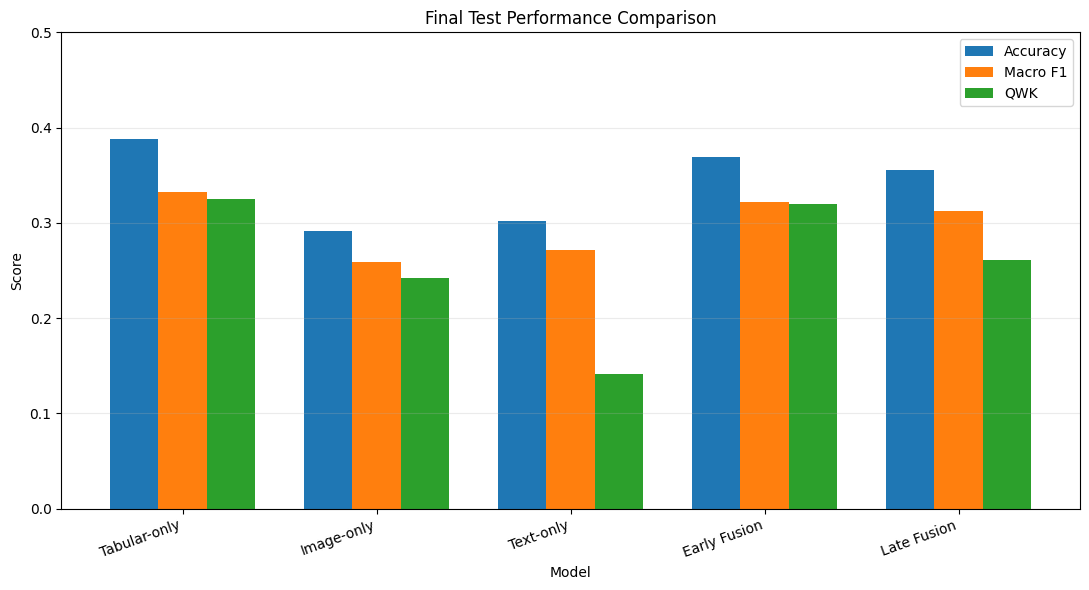

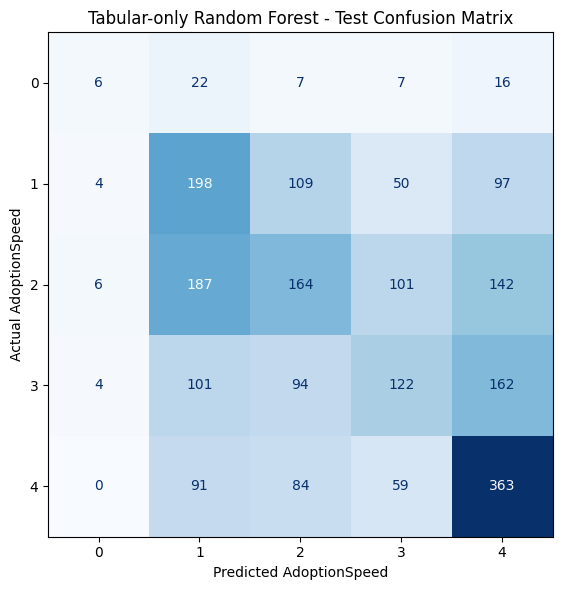

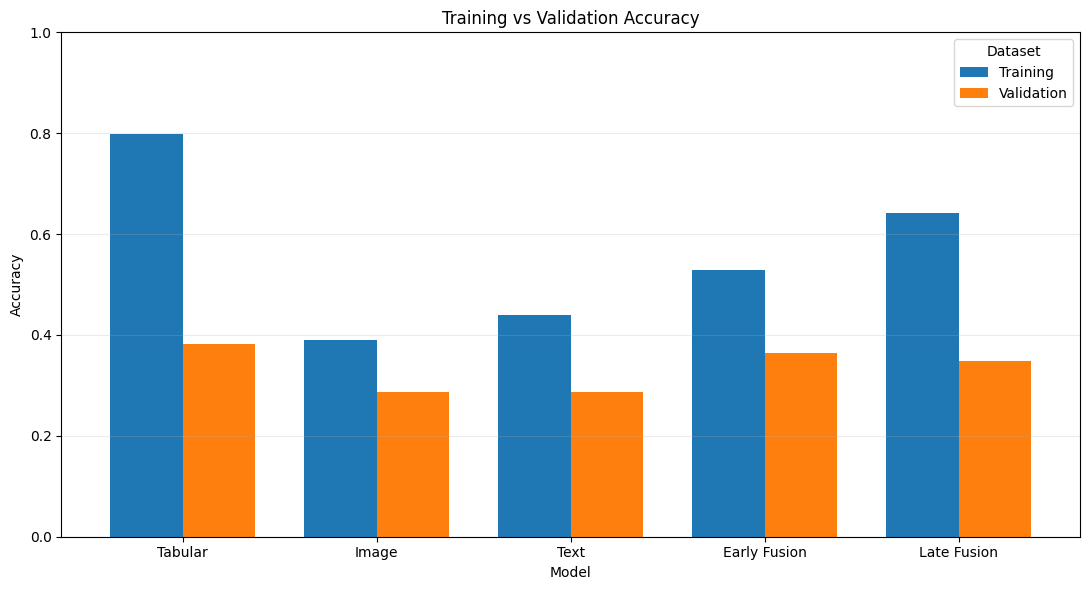

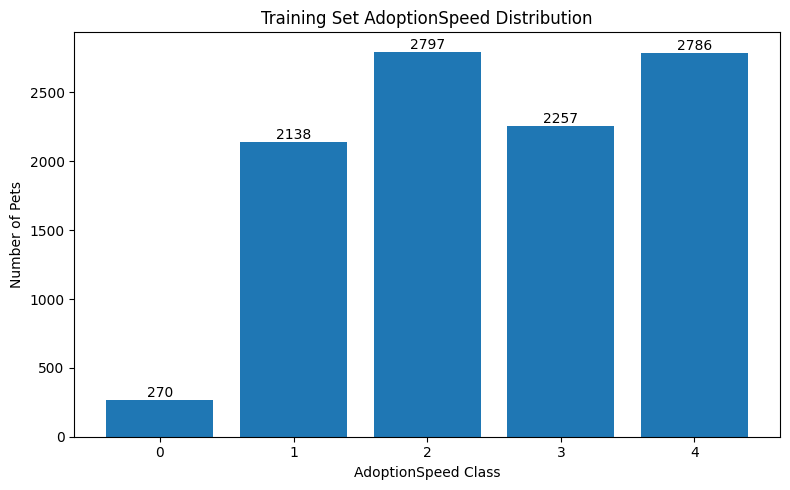

=== Final Report Figures Completed ===
All 4 figures generated successfully!
figure1_model_comparison.png
figure2_confusion_matrix.png
figure3_overfitting.png
figure4_class_distribution.png


In [40]:

# Cell 38 - Generate All Final Report Figures

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Output folders
figures_dir = "/content/petfinder/figures"

os.makedirs(figures_dir, exist_ok=True)

# ==========================================
# Figure 1 - Model Performance Comparison
# Keep original style and results
# ==========================================

plot_df = final_test_df.set_index("Model")[
    ["Accuracy", "Macro_F1", "QWK"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Final Test Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 0.5)
plt.xticks(rotation=20, ha="right")
plt.legend(["Accuracy", "Macro F1", "QWK"])
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{figures_dir}/figure1_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ==========================================
# Figure 2 - Confusion Matrix
# Keep original style and results
# ==========================================

cm = confusion_matrix(
    y_test,
    tab_test_pred,
    labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Tabular-only Random Forest - Test Confusion Matrix")
plt.xlabel("Predicted AdoptionSpeed")
plt.ylabel("Actual AdoptionSpeed")
plt.tight_layout()

plt.savefig(
    f"{figures_dir}/figure2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ==========================================
# Figure 3 - Improved Overfitting Analysis
# Shorter model names and consistent order
# ==========================================

model_names = {
    "Random Forest (Tabular)": "Tabular",
    "Image-only (ResNet18 + Logistic Regression)": "Image",
    "Text-only (Multilingual BERT + Logistic Regression)": "Text",
    "Early Fusion (Tabular + Image + Text)": "Early Fusion",
    "Late Fusion (Probability Averaging)": "Late Fusion"
}

overfit_df = final_model_results.copy()
overfit_df["Model"] = overfit_df["Model"].replace(model_names)

accuracy_df = overfit_df.pivot(
    index="Model",
    columns="Dataset",
    values="Accuracy"
)

model_order = [
    "Tabular",
    "Image",
    "Text",
    "Early Fusion",
    "Late Fusion"
]

accuracy_df = accuracy_df.loc[
    model_order,
    ["Training", "Validation"]
]

accuracy_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Training vs Validation Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{figures_dir}/figure3_overfitting.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ==========================================
# Figure 4 - Class Distribution
# Keep original style and results
# ==========================================

class_counts = pd.Series(y_train).value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.title("Training Set AdoptionSpeed Distribution")
plt.xlabel("AdoptionSpeed Class")
plt.ylabel("Number of Pets")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    f"{figures_dir}/figure4_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ==========================================
print("=== Final Report Figures Completed ===")
print("All four figures saved locally.")
print(sorted(f for f in os.listdir(figures_dir) if f.endswith(".png")))
